# Primera comparación

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "resultados"

In [3]:
basal_metrics = pd.read_csv(RESULTS_DIR / "basal_metricas_validation.csv")
tda_metrics = pd.read_csv(RESULTS_DIR / "tda_metricas_validation.csv")

basal_pred = pd.read_csv(
    RESULTS_DIR / "basal_predicciones_validation.csv"
).set_index("track_id").sort_index()

tda_pred = pd.read_csv(
    RESULTS_DIR / "tda_predicciones_validation.csv"
).set_index("track_id").sort_index()

if not basal_pred.index.is_unique or not tda_pred.index.is_unique:
    raise ValueError("Hay track_id repetidos en las predicciones.")

if (
    not basal_pred.index.equals(tda_pred.index)
    or not basal_pred["genre_real"].equals(tda_pred["genre_real"])
):
    raise ValueError("Los modelos no evaluaron las mismas pistas de validation.")

if set(basal_metrics["modelo"]) != set(tda_metrics["modelo"]):
    raise ValueError("Los archivos de métricas no contienen los mismos clasificadores.")

In [4]:
comparison = pd.concat([
    basal_metrics.assign(configuracion="Basal"),
    tda_metrics.assign(configuracion="Aumentado")
], ignore_index=True)[
    ["modelo", "configuracion", "accuracy_validation", "f1_ponderado_validation"]
].sort_values(["modelo", "configuracion"])

base = basal_metrics.set_index("modelo")[
    ["accuracy_validation", "f1_ponderado_validation"]
]
aug = tda_metrics.set_index("modelo")[
    ["accuracy_validation", "f1_ponderado_validation"]
]

differences = (aug - base).rename(columns={
    "accuracy_validation": "diferencia_accuracy",
    "f1_ponderado_validation": "diferencia_f1_ponderado"
}).reset_index()

display(comparison.round(4))
display(differences.round(4))

comparison.to_csv(RESULTS_DIR / "comparacion_validation.csv", index=False)
differences.to_csv(RESULTS_DIR / "diferencias_validation.csv", index=False)

,modelo,configuracion,accuracy_validation,f1_ponderado_validation
3,Random Forest,Aumentado,0.5567,0.4998
0,Random Forest,Basal,0.5418,0.4879
4,SVM RBF,Aumentado,0.5702,0.5282
1,SVM RBF,Basal,0.5484,0.5060
5,XGBoost,Aumentado,0.5767,0.5404
2,XGBoost,Basal,0.5310,0.4844


,modelo,diferencia_accuracy,diferencia_f1_ponderado
0,Random Forest,0.0148,0.0119
1,SVM RBF,0.0218,0.0222
2,XGBoost,0.0458,0.0560


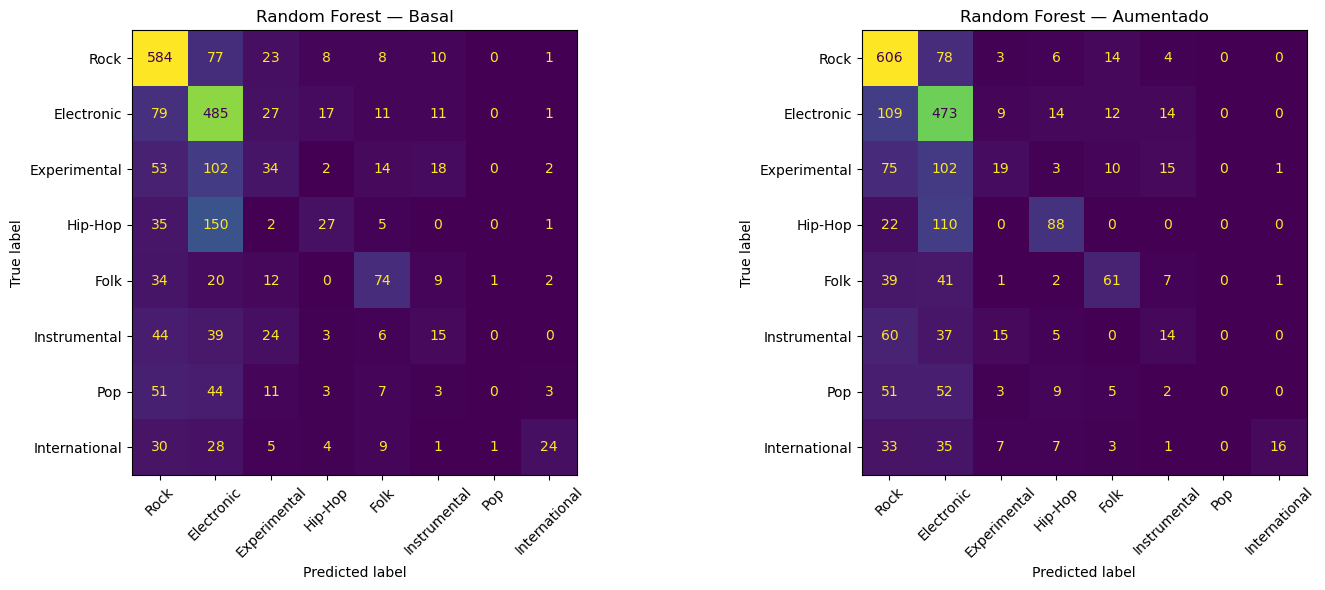

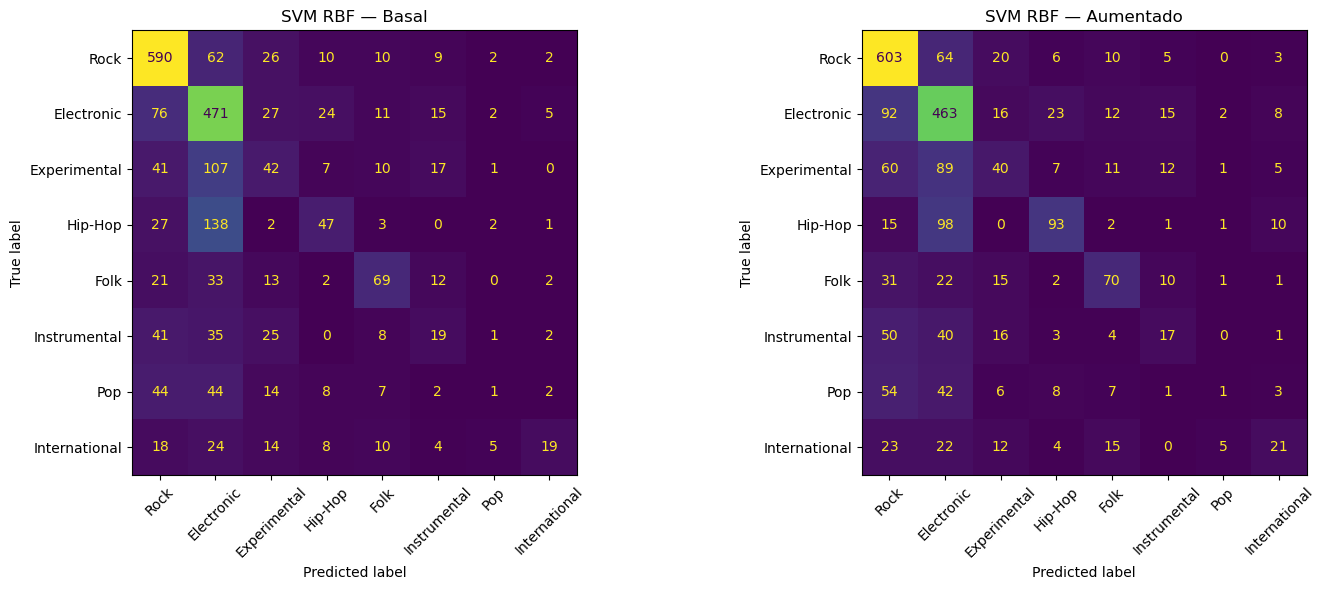

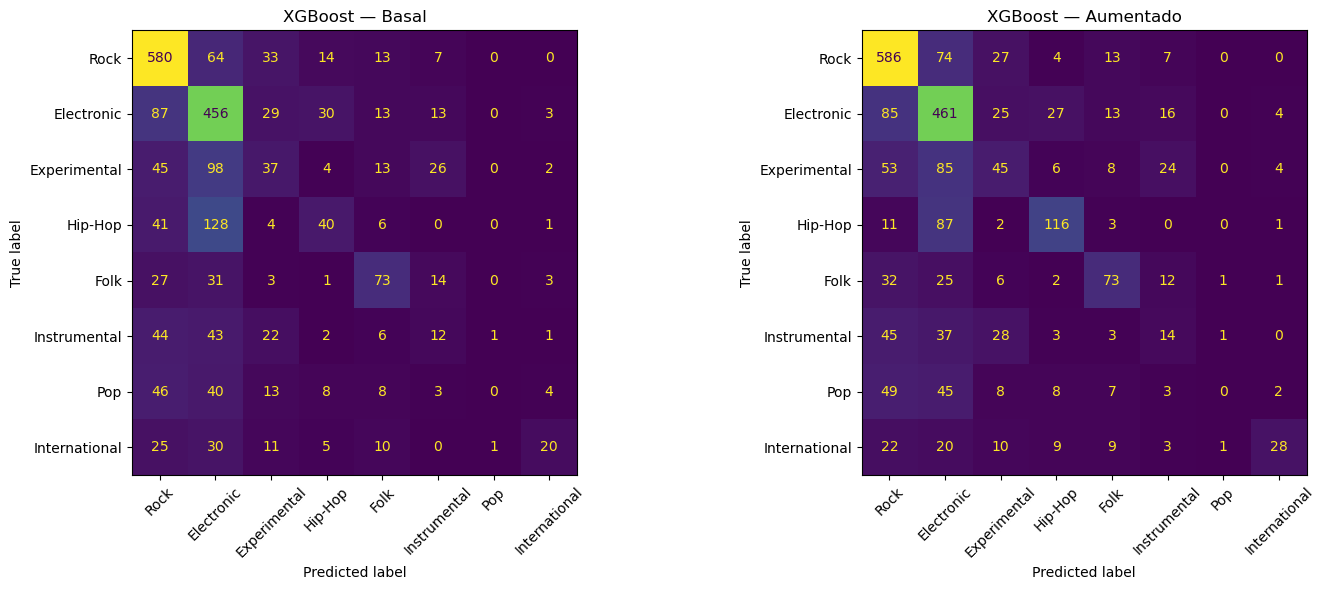

In [5]:
genres = [
    "Rock", "Electronic", "Experimental", "Hip-Hop",
    "Folk", "Instrumental", "Pop", "International"
]

for model in basal_metrics["modelo"]:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for ax, title, data in zip(
        axes,
        ["Basal", "Aumentado"],
        [basal_pred, tda_pred]
    ):
        ConfusionMatrixDisplay.from_predictions(
            data["genre_real"],
            data[model],
            labels=genres,
            values_format="d",
            xticks_rotation=45,
            colorbar=False,
            ax=ax
        )
        ax.set_title(f"{model} — {title}")

    plt.tight_layout()
    plt.show()

## Comparación final de la configuración E

Los experimentos originales siguen documentados por separado. Esta sección evalúa la ampliación seleccionada mediante validación cruzada: 56 atributos acústicos, 300 estimadores para Random Forest y XGBoost, y sin pesos de clase. TDA añade 800 atributos de Persistence Images; no se aplica PCA.

Se entrena con `training + validation` y se evalúa una sola vez sobre el `test` oficial. Las dos versiones de cada clasificador utilizan las mismas pistas.

In [6]:
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gtda.diagrams import PersistenceImage
from gtda.homology import VietorisRipsPersistence

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

PROJECT_DIR = Path.cwd()
AUDIO_DIR = Path(os.environ.get("FMA_AUDIO_DIR", str(PROJECT_DIR / "fma_medium")))
RESULTS_DIR = PROJECT_DIR / "resultados"
DIAGRAMS_DIR = RESULTS_DIR / "diagramas_tda"

SEED = 42
SR = 22050
DURATION = 30
N_FFT = 1024
HOP_LENGTH = 512
SIGMA = 0.5
N_BINS = 20

GENRES = [
    "Rock", "Electronic", "Experimental", "Hip-Hop",
    "Folk", "Instrumental", "Pop", "International"
]

# Compatibilidad de giotto-tda con NumPy 2.
if not hasattr(np, "product"):
    np.product = np.prod

### Resultados que justifican la elección

Se reúnen los resultados de validación cruzada obtenidos en `training`. B y E se comparan en ambos pipelines; F se muestra como alternativa evaluada únicamente en TDA.

In [7]:
basal_cv = (
    pd.read_csv(RESULTS_DIR / "basal_ultima_cv.csv")
    .rename(columns={
        "accuracy": "accuracy_cv",
        "f1_ponderado": "f1_cv"
    })
    .assign(pipeline="Basal")
)

tda_cv = (
    pd.read_csv(RESULTS_DIR / "tda_ultima_cv.csv")
    .assign(pipeline="TDA")
)

cv_table = pd.concat([
    basal_cv[
        basal_cv["configuracion"].isin(
            ["B_atributos", "E_sin_pesos_300"]
        )
    ],
    tda_cv[
        tda_cv["configuracion"].isin(
            ["B_atributos", "E_sin_pesos_300", "F_pca_100"]
        )
    ]
], ignore_index=True)

cv_summary = cv_table.groupby(
    ["pipeline", "configuracion"]
)[["accuracy_cv", "f1_cv"]].mean()

display(cv_summary.round(4))

e_scores = cv_table[
    cv_table["configuracion"] == "E_sin_pesos_300"
]

basal_e = e_scores[e_scores["pipeline"] == "Basal"].set_index("modelo")
tda_e = e_scores[e_scores["pipeline"] == "TDA"].set_index("modelo")

cv_comparison = basal_e[["accuracy_cv", "f1_cv"]].join(
    tda_e[["accuracy_cv", "f1_cv"]],
    lsuffix="_basal",
    rsuffix="_tda"
)

cv_comparison["delta_accuracy"] = (
    cv_comparison["accuracy_cv_tda"]
    - cv_comparison["accuracy_cv_basal"]
)
cv_comparison["delta_f1"] = (
    cv_comparison["f1_cv_tda"]
    - cv_comparison["f1_cv_basal"]
)

display(cv_comparison.round(4))
cv_comparison.to_csv(RESULTS_DIR / "comparacion_E_cv.csv")

accuracy_cv   f1_cv
pipeline configuracion                       
Basal    B_atributos           0.6144  0.5859
         E_sin_pesos_300       0.6182  0.5899
TDA      B_atributos           0.6090  0.5748
         E_sin_pesos_300       0.6131  0.5792
         F_pca_100             0.6106  0.5760

,accuracy_cv_basal,f1_cv_basal,accuracy_cv_tda,f1_cv_tda,delta_accuracy,delta_f1
modelo,,,,,,
Random Forest,0.6018,0.5615,0.5910,0.5425,-0.0108,-0.0190
SVM RBF,0.6287,0.6131,0.6177,0.5922,-0.0110,-0.0209
XGBoost,0.6240,0.5951,0.6305,0.6030,0.0065,0.0079


### Pistas de entrenamiento y prueba

Se utilizan los mismos `track_id`, géneros y 56 atributos acústicos en ambas versiones. `test` permanece separado hasta calcular las predicciones finales.

In [8]:
base = (
    pd.read_csv(RESULTS_DIR / "caracteristicas_basales.csv")
    .set_index("track_id")
    .sort_index()
)

acoustic = (
    pd.read_csv(RESULTS_DIR / "caracteristicas_acusticas_56.csv")
    .set_index("track_id")
    .sort_index()
)

if not base.index.equals(acoustic.index):
    raise ValueError("Los archivos acústicos no tienen los mismos track_id.")

cols_16 = [f"mfcc_{i}" for i in range(13)] + [
    "centroid", "rolloff", "zcr"
]
cols_56 = (
    cols_16
    + [f"mfcc_mean_{i}" for i in range(13, 20)]
    + [f"mfcc_std_{i}" for i in range(20)]
    + ["centroid_std"]
    + [f"chroma_mean_{i}" for i in range(12)]
)

fit_ids = base.index[base["split"].isin(["training", "validation"])]
test_ids = base.index[base["split"] == "test"]

y_fit = base.loc[fit_ids, "genre"].to_numpy()
y_test = base.loc[test_ids, "genre"].to_numpy()

X_basal_fit = acoustic.loc[fit_ids, cols_56].to_numpy()
X_basal_test = acoustic.loc[test_ids, cols_56].to_numpy()

print("Entrenamiento:", len(fit_ids), "| Test:", len(test_ids))

Entrenamiento: 20587 | Test: 2334


### Diagramas topológicos de `test`

Se reutilizan los diagramas ya calculados para `training` y `validation`. Únicamente se calculan los diagramas que faltan de `test`, aplicando exactamente la extracción MFCC y Vietoris–Rips del notebook TDA.

In [9]:
DIAGRAMS_DIR.mkdir(parents=True, exist_ok=True)

def mfcc_cloud(track_id):
    filename = f"{track_id:06d}"
    path = AUDIO_DIR / filename[:3] / f"{filename}.mp3"

    audio, _ = librosa.load(
        path, sr=SR, mono=True, duration=DURATION
    )
    if len(audio) < N_FFT:
        raise ValueError(f"Audio demasiado corto: {path}")

    audio = audio / max(np.max(np.abs(audio)), 1e-12)

    spectrum = np.abs(
        librosa.stft(
            audio, n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            window="hamming"
        )
    )
    mel = librosa.feature.melspectrogram(S=spectrum**2, sr=SR)
    mfcc = librosa.feature.mfcc(
        S=librosa.power_to_db(mel), n_mfcc=13
    )

    return mfcc.T


rips = VietorisRipsPersistence(
    metric="euclidean",
    homology_dimensions=(0, 1),
    coeff=2,
    reduced_homology=True
)

for number, track_id in enumerate(test_ids, start=1):
    path = DIAGRAMS_DIR / f"{track_id:06d}.npy"

    if not path.exists():
        diagram = rips.fit_transform([mfcc_cloud(int(track_id))])[0]
        np.save(path, diagram)

    if number % 250 == 0 or number == len(test_ids):
        print(f"Test: {number}/{len(test_ids)} diagramas revisados")

Test: 250/2334 diagramas revisados


Test: 500/2334 diagramas revisados


Test: 750/2334 diagramas revisados


Test: 1000/2334 diagramas revisados


Test: 1250/2334 diagramas revisados


Test: 1500/2334 diagramas revisados


Test: 1750/2334 diagramas revisados


Test: 2000/2334 diagramas revisados


Test: 2250/2334 diagramas revisados


Test: 2334/2334 diagramas revisados


### Persistence Images finales

La rejilla de las Persistence Images se ajusta con `training + validation`. Después se transforma `test`, sin utilizar sus datos para ajustar esa rejilla. Se conserva la ponderación por persistencia empleada en el notebook TDA.

In [10]:
def pad_diagrams(items):
    n0 = max((d[:, 2] == 0).sum() for d in items)
    n1 = max(1, max((d[:, 2] == 1).sum() for d in items))

    padded = np.zeros((len(items), n0 + n1, 3), dtype=np.float32)
    padded[:, n0:, 2] = 1

    for i, diagram in enumerate(items):
        h0 = diagram[diagram[:, 2] == 0]
        h1 = diagram[diagram[:, 2] == 1]
        padded[i, :len(h0)] = h0
        padded[i, n0:n0 + len(h1)] = h1

    return padded


def linear_weight(persistence):
    return persistence


def pi_features(pi, diagrams):
    images = pi.transform(diagrams)
    persistence = diagrams[:, :, 1] - diagrams[:, :, 0]

    for channel, dim in enumerate(pi.homology_dimensions_):
        maximum = np.where(
            diagrams[:, :, 2] == dim, persistence, 0
        ).max(axis=1)

        images[:, channel] /= np.maximum(
            maximum, 1e-12
        )[:, None, None]

    return images.reshape(len(diagrams), -1)


fit_diagrams = [
    np.load(DIAGRAMS_DIR / f"{track_id:06d}.npy")
    for track_id in fit_ids
]
test_diagrams = [
    np.load(DIAGRAMS_DIR / f"{track_id:06d}.npy")
    for track_id in test_ids
]

D_fit = pad_diagrams(fit_diagrams)
D_test = pad_diagrams(test_diagrams)

pi = PersistenceImage(
    sigma=SIGMA,
    n_bins=N_BINS,
    weight_function=linear_weight
)
pi.fit(D_fit)

X_pi_fit = pi_features(pi, D_fit)
X_pi_test = pi_features(pi, D_test)

X_tda_fit = np.hstack([X_basal_fit, X_pi_fit])
X_tda_test = np.hstack([X_basal_test, X_pi_test])

del fit_diagrams, test_diagrams, D_fit, D_test

print("Basal:", X_basal_fit.shape[1], "atributos")
print("TDA:", X_tda_fit.shape[1], "atributos")

Basal: 56 atributos
TDA: 856 atributos


### Persistence Images finales

La rejilla de las Persistence Images se ajusta con `training + validation`. Después se transforma `test`, sin utilizar sus datos para ajustar esa rejilla. Se conserva la ponderación por persistencia empleada en el notebook TDA.

In [11]:
def pad_diagrams(items):
    n0 = max((d[:, 2] == 0).sum() for d in items)
    n1 = max(1, max((d[:, 2] == 1).sum() for d in items))

    padded = np.zeros((len(items), n0 + n1, 3), dtype=np.float32)
    padded[:, n0:, 2] = 1

    for i, diagram in enumerate(items):
        h0 = diagram[diagram[:, 2] == 0]
        h1 = diagram[diagram[:, 2] == 1]
        padded[i, :len(h0)] = h0
        padded[i, n0:n0 + len(h1)] = h1

    return padded


def linear_weight(persistence):
    return persistence


def pi_features(pi, diagrams):
    images = pi.transform(diagrams)
    persistence = diagrams[:, :, 1] - diagrams[:, :, 0]

    for channel, dim in enumerate(pi.homology_dimensions_):
        maximum = np.where(
            diagrams[:, :, 2] == dim, persistence, 0
        ).max(axis=1)

        images[:, channel] /= np.maximum(
            maximum, 1e-12
        )[:, None, None]

    return images.reshape(len(diagrams), -1)


fit_diagrams = [
    np.load(DIAGRAMS_DIR / f"{track_id:06d}.npy")
    for track_id in fit_ids
]
test_diagrams = [
    np.load(DIAGRAMS_DIR / f"{track_id:06d}.npy")
    for track_id in test_ids
]

D_fit = pad_diagrams(fit_diagrams)
D_test = pad_diagrams(test_diagrams)

pi = PersistenceImage(
    sigma=SIGMA,
    n_bins=N_BINS,
    weight_function=linear_weight
)
pi.fit(D_fit)

X_pi_fit = pi_features(pi, D_fit)
X_pi_test = pi_features(pi, D_test)

X_tda_fit = np.hstack([X_basal_fit, X_pi_fit])
X_tda_test = np.hstack([X_basal_test, X_pi_test])

del fit_diagrams, test_diagrams, D_fit, D_test

print("Basal:", X_basal_fit.shape[1], "atributos")
print("TDA:", X_tda_fit.shape[1], "atributos")

Basal: 56 atributos
TDA: 856 atributos


### Modelos finales y predicciones

Random Forest y XGBoost usan 300 estimadores en ambos pipelines. Los parámetros SVM se recuperan de las búsquedas anteriores: la SVM basal de E es idéntica a la de B, y la SVM TDA de E reutiliza los parámetros obtenidos para TDA B.

In [12]:
basal_experiment = pd.read_csv(
    RESULTS_DIR / "basal_experimento_cv.csv"
)

basal_svm = basal_experiment.loc[
    (basal_experiment["configuracion"] == "B_atributos")
    & (basal_experiment["modelo"] == "SVM RBF")
].iloc[0]

tda_svm = tda_cv.loc[
    (tda_cv["configuracion"] == "E_sin_pesos_300")
    & (tda_cv["modelo"] == "SVM RBF")
].iloc[0]


def svm_params(row):
    gamma = row["gamma"]
    gamma = "scale" if str(gamma) == "scale" else float(gamma)
    return {"C": float(row["C"]), "gamma": gamma}


encoder = LabelEncoder().fit(y_fit)

predictions_test = pd.DataFrame({
    "track_id": test_ids,
    "genre_real": y_test
})
metric_rows = []

for pipeline, X_fit, X_eval, svm_row in [
    ("Basal", X_basal_fit, X_basal_test, basal_svm),
    ("TDA", X_tda_fit, X_tda_test, tda_svm)
]:
    forest = RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        criterion="gini",
        random_state=SEED
    ).fit(X_fit, y_fit)

    svm = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", **svm_params(svm_row))
    ).fit(X_fit, y_fit)

    boost = XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=6,
        random_state=SEED
    ).fit(X_fit, encoder.transform(y_fit))

    current_predictions = {
        "Random Forest": forest.predict(X_eval),
        "SVM RBF": svm.predict(X_eval),
        "XGBoost": encoder.inverse_transform(
            boost.predict(X_eval).astype(int)
        )
    }

    for model, predicted in current_predictions.items():
        predictions_test[f"{pipeline} {model}"] = predicted
        metric_rows.append({
            "pipeline": pipeline,
            "modelo": model,
            "accuracy": accuracy_score(y_test, predicted),
            "f1_ponderado": f1_score(
                y_test, predicted, average="weighted"
            )
        })

metrics_test = pd.DataFrame(metric_rows)

### Comparación en `test`

Para cada clasificador se resta la métrica basal de la métrica TDA. Las diferencias son descriptivas: indican qué ocurrió en estas pistas, sin afirmar por sí solas que la mejora sea estadísticamente significativa.

In [13]:
basal_test = (
    metrics_test[metrics_test["pipeline"] == "Basal"]
    .set_index("modelo")[["accuracy", "f1_ponderado"]]
)

tda_test = (
    metrics_test[metrics_test["pipeline"] == "TDA"]
    .set_index("modelo")[["accuracy", "f1_ponderado"]]
)

comparison_test = basal_test.join(
    tda_test,
    lsuffix="_basal",
    rsuffix="_tda"
)

comparison_test["delta_accuracy"] = (
    comparison_test["accuracy_tda"]
    - comparison_test["accuracy_basal"]
)
comparison_test["delta_f1_ponderado"] = (
    comparison_test["f1_ponderado_tda"]
    - comparison_test["f1_ponderado_basal"]
)

display(comparison_test.round(4))

comparison_test.to_csv(
    RESULTS_DIR / "comparacion_final_test.csv"
)
predictions_test.to_csv(
    RESULTS_DIR / "comparacion_final_predicciones_test.csv",
    index=False
)

,accuracy_basal,f1_ponderado_basal,accuracy_tda,f1_ponderado_tda,delta_accuracy,delta_f1_ponderado
modelo,,,,,,
Random Forest,0.5724,0.5225,0.5664,0.5061,-0.0060,-0.0163
SVM RBF,0.5638,0.5407,0.5844,0.5499,0.0206,0.0092
XGBoost,0.5908,0.5523,0.5913,0.5548,0.0004,0.0026


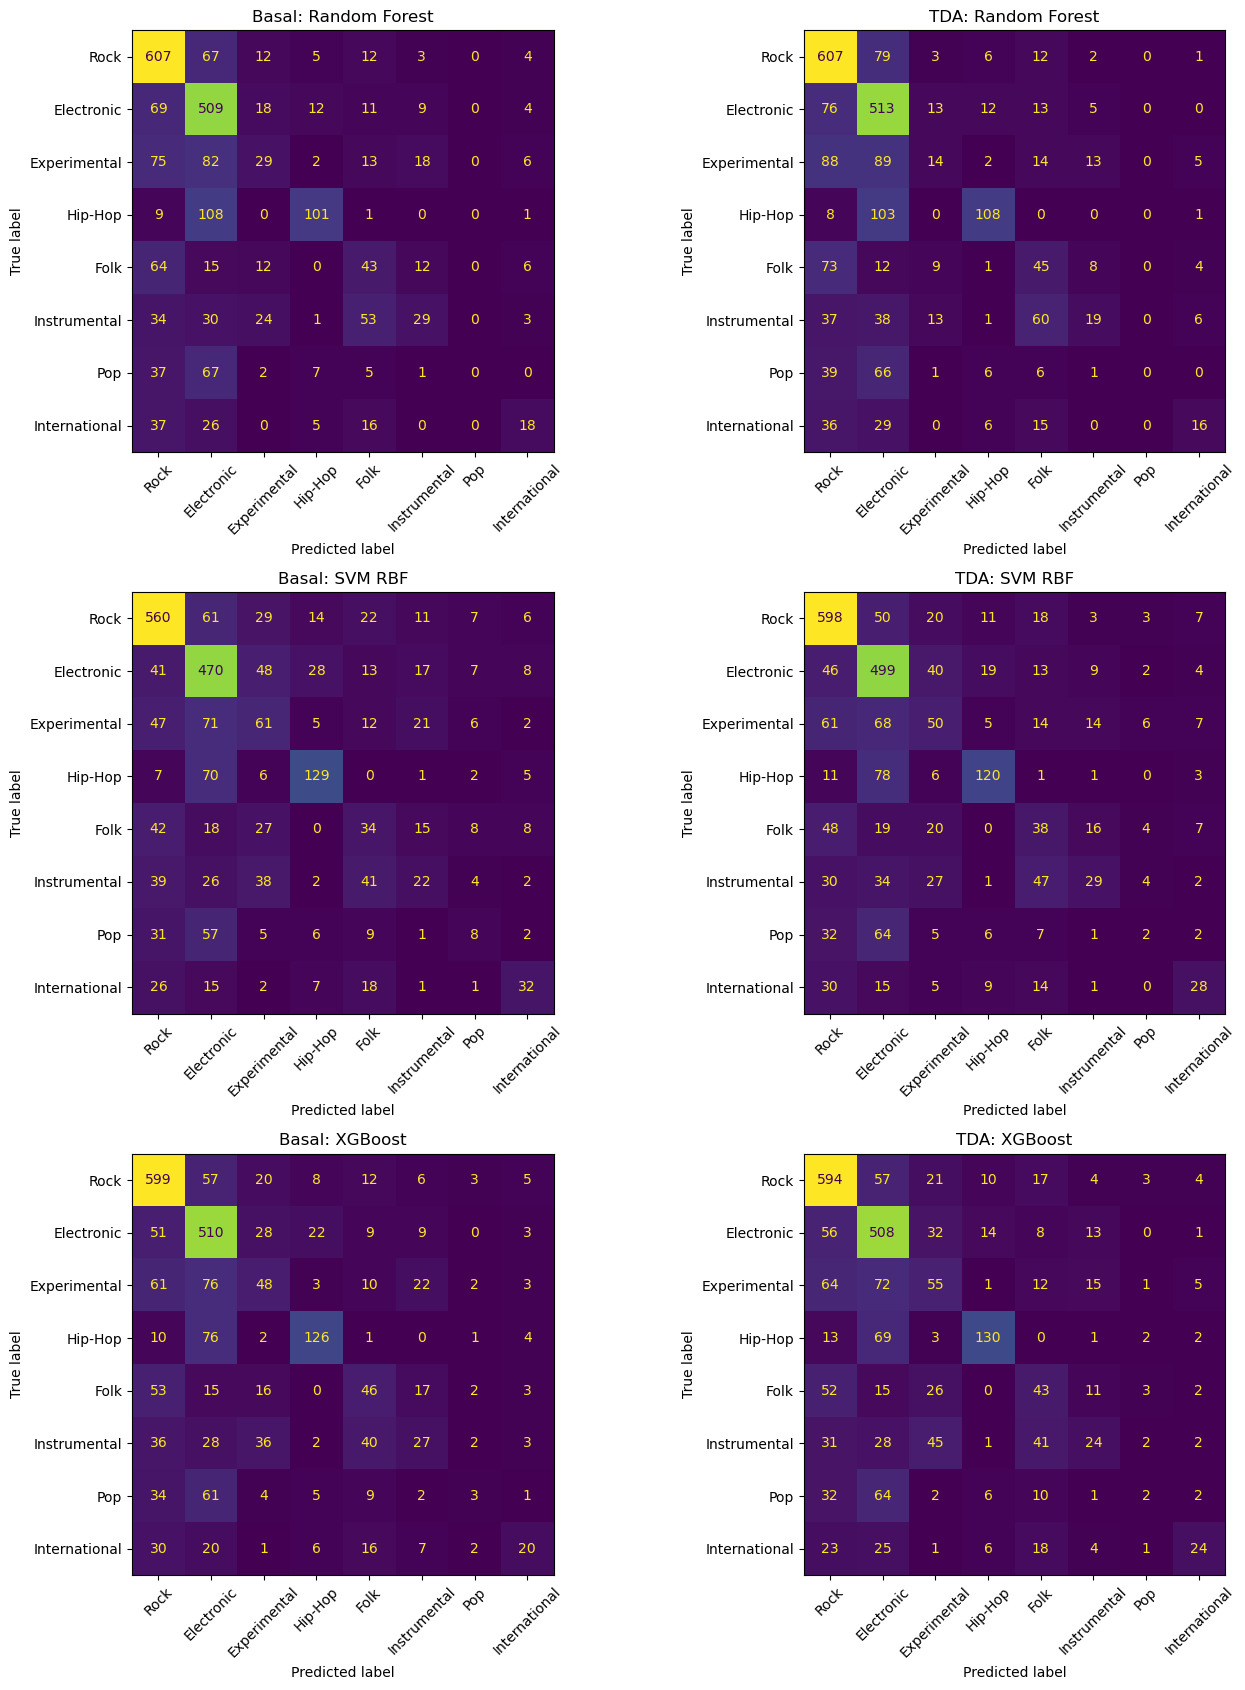

In [14]:
models = ["Random Forest", "SVM RBF", "XGBoost"]
fig, axes = plt.subplots(3, 2, figsize=(14, 17))

for i, model in enumerate(models):
    for j, pipeline in enumerate(["Basal", "TDA"]):
        ConfusionMatrixDisplay.from_predictions(
            y_test,
            predictions_test[f"{pipeline} {model}"],
            labels=GENRES,
            xticks_rotation=45,
            values_format="d",
            colorbar=False,
            ax=axes[i, j]
        )
        axes[i, j].set_title(f"{pipeline}: {model}")

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "matrices_confusion_final_test.png",
    dpi=150
)
plt.show()

## Evaluación complementaria

Se calculan métricas por género y F1 macro para describir cómo se distribuye
el rendimiento entre clases. Después se compara la accuracy de los modelos
basal y aumentado mediante McNemar.

Este análisis complementa la evaluación final y no se utiliza para ajustar
los modelos.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support

RESULTS_DIR = Path.cwd() / "resultados"

MODELOS = ["Random Forest", "SVM RBF", "XGBoost"]
ALPHA = 0.05  # Umbral convencional para las pruebas estadísticas.

predicciones = pd.read_csv(
    RESULTS_DIR / "comparacion_final_predicciones_test.csv"
)

reales = predicciones["genre_real"]
generos = sorted(reales.unique())

### Rendimiento por género

La precisión indica qué proporción de las predicciones de un género es correcta.
El recall indica qué proporción de sus pistas reales se identifica correctamente.
F1 combina ambas medidas.

F1 macro promedia el F1 de los géneros dando el mismo peso a cada uno.
Las diferencias se calculan como TDA menos basal.

In [16]:
filas_macro = []
tablas_genero = []

for modelo in MODELOS:
    for version in ["Basal", "TDA"]:
        precision, recall, f1, soporte = precision_recall_fscore_support(
            reales,
            predicciones[f"{version} {modelo}"],
            labels=generos,
            zero_division=0
        )

        filas_macro.append({
            "modelo": modelo,
            "pipeline": version,
            "f1_macro": f1.mean()
        })

        tablas_genero.append(pd.DataFrame({
            "modelo": modelo,
            "pipeline": version,
            "genero": generos,
            "n_pistas": soporte,
            "precision": precision,
            "recall": recall,
            "f1": f1
        }))

por_genero = pd.concat(tablas_genero, ignore_index=True)

macro = pd.DataFrame(filas_macro).pivot(
    index="modelo",
    columns="pipeline",
    values="f1_macro"
).loc[MODELOS]

macro["delta_f1_macro"] = macro["TDA"] - macro["Basal"]

display(macro.round(4))
display(por_genero.round(4))

macro.to_csv(RESULTS_DIR / "comparacion_f1_macro_test.csv")
por_genero.to_csv(RESULTS_DIR / "metricas_por_genero_test.csv", index=False)

pipeline,Basal,TDA,delta_f1_macro
modelo,,,
Random Forest,0.3652,0.3465,-0.0187
SVM RBF,0.3983,0.3964,-0.0020
XGBoost,0.3978,0.4034,0.0056


,modelo,pipeline,genero,n_pistas,precision,recall,f1
0,Random Forest,Basal,Electronic,632,0.5631,0.8054,0.6628
1,Random Forest,Basal,Experimental,225,0.2990,0.1289,0.1801
2,Random Forest,Basal,Folk,152,0.2792,0.2829,0.2810
3,Random Forest,Basal,Hip-Hop,220,0.7594,0.4591,0.5722
4,Random Forest,Basal,Instrumental,174,0.4028,0.1667,0.2358
5,Random Forest,Basal,International,102,0.4286,0.1765,0.2500
6,Random Forest,Basal,Pop,119,0.0000,0.0000,0.0000
7,Random Forest,Basal,Rock,710,0.6513,0.8549,0.7393
8,Random Forest,TDA,Electronic,632,0.5522,0.8117,0.6573
9,Random Forest,TDA,Experimental,225,0.2642,0.0622,0.1007


### Comparación pareada de accuracy

McNemar compara las pistas que solo acierta el basal con las que solo acierta
TDA. Se utiliza la versión exacta bilateral, que permite detectar diferencias
en cualquier dirección.

Se aplica el ajuste de Holm a las tres comparaciones para controlar el error
por realizar varias pruebas. Se utiliza un nivel de significación de 0.05.

La prueba considera las pistas como observaciones independientes; no modela
la posible dependencia entre canciones del mismo artista o álbum.

In [17]:
filas_pruebas = []

for modelo in MODELOS:
    basal_ok = predicciones[f"Basal {modelo}"].eq(reales)
    tda_ok = predicciones[f"TDA {modelo}"].eq(reales)

    solo_basal = int((basal_ok & ~tda_ok).sum())
    solo_tda = int((~basal_ok & tda_ok).sum())
    desacuerdos = solo_basal + solo_tda

    if desacuerdos == 0:
        p_valor = 1.0
    else:
        p_valor = binomtest(
            solo_tda,
            desacuerdos,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    filas_pruebas.append({
        "modelo": modelo,
        "solo_basal": solo_basal,
        "solo_tda": solo_tda,
        "delta_accuracy_pp": 100 * (tda_ok.mean() - basal_ok.mean()),
        "p_mcnemar": p_valor
    })

pruebas = pd.DataFrame(filas_pruebas).sort_values("p_mcnemar")

# Holm: ordenar los valores p y aplicar los factores 3, 2 y 1.
factores = np.arange(len(pruebas), 0, -1)
pruebas["p_holm"] = (
    pruebas["p_mcnemar"] * factores
).cummax().clip(upper=1)

pruebas["diferencia_significativa"] = pruebas["p_holm"] <= ALPHA
pruebas = pruebas.set_index("modelo").loc[MODELOS]

display(pruebas.round(6))
pruebas.to_csv(RESULTS_DIR / "mcnemar_holm_test.csv")

,solo_basal,solo_tda,delta_accuracy_pp,p_mcnemar,p_holm,diferencia_significativa
modelo,,,,,,
Random Forest,76,62,-0.599829,0.26839,0.53678,False
SVM RBF,126,174,2.056555,0.00656,0.01968,True
XGBoost,83,84,0.042845,1.00000,1.00000,False


# Prueba 16 y 816 atributos

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

from gtda.diagrams import PersistenceImage
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier
from scipy.stats import binomtest
from IPython.display import display

# Compatibilidad con giotto-tda.
if not hasattr(np, "product"):
    np.product = np.prod

RESULTS_DIR = Path.cwd() / "resultados"
DIAGRAMS_DIR = RESULTS_DIR / "diagramas_tda"

# Recuperar los 16 atributos originales.
data = pd.read_csv(
    RESULTS_DIR / "caracteristicas_basales.csv"
).set_index("track_id").sort_index()

cols = [f"mfcc_{i}" for i in range(13)] + ["centroid", "rolloff", "zcr"]

# Ajustar con entrenamiento + validación; evaluar en test.
fit = data["split"].isin(["training", "validation"])
test = data["split"].eq("test")

X_fit = data.loc[fit, cols].to_numpy()
X_test = data.loc[test, cols].to_numpy()

encoder = LabelEncoder().fit(data.loc[fit, "genre"])
y_fit = encoder.transform(data.loc[fit, "genre"])
y_test = encoder.transform(data.loc[test, "genre"])

# Dos imágenes de 20 × 20: 800 atributos topológicos.
pi = PersistenceImage(
    sigma=0.5, n_bins=20, weight_function=lambda p: p
)

def topologia(ids, ajustar=False):
    diagrams = [
        np.load(DIAGRAMS_DIR / f"{track_id:06d}.npy")
        for track_id in ids
    ]

    n0 = max(1, max((d[:, 2] == 0).sum() for d in diagrams))
    n1 = max(1, max((d[:, 2] == 1).sum() for d in diagrams))

    # Igualar tamaños con puntos de persistencia cero.
    D = np.zeros((len(diagrams), n0 + n1, 3), dtype=np.float32)
    D[:, n0:, 2] = 1

    for i, d in enumerate(diagrams):
        h0, h1 = d[d[:, 2] == 0], d[d[:, 2] == 1]
        D[i, :len(h0)] = h0
        D[i, n0:n0 + len(h1)] = h1

    if ajustar:
        pi.fit(D)

    images = pi.transform(D)
    persistence = D[:, :, 1] - D[:, :, 0]

    # Normalización utilizada en el notebook original.
    for channel, dim in enumerate(pi.homology_dimensions_):
        maximum = np.where(
            D[:, :, 2] == dim, persistence, 0
        ).max(axis=1)

        images[:, channel] /= np.maximum(
            maximum, 1e-12
        )[:, None, None]

    return images.reshape(len(ids), -1)

X_tda_fit = np.hstack([X_fit, topologia(data.index[fit], ajustar=True)])
X_tda_test = np.hstack([X_test, topologia(data.index[test])])

assert X_fit.shape[1] == 16 and X_tda_fit.shape[1] == 816

# Parámetros originales, sin pesos de clase ni PCA.
results = []
predicciones = {}

for version, train_X, test_X, gamma in [
    ("Basal", X_fit, X_test, "scale"),
    ("TDA", X_tda_fit, X_tda_test, 0.01)
]:
    models = {
        "Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=20, random_state=42
        ),
        "SVM RBF": make_pipeline(
            StandardScaler(),
            SVC(C=10, gamma=gamma, kernel="rbf")
        ),
        "XGBoost": XGBClassifier(
            n_estimators=100, max_depth=6,
            learning_rate=0.1, random_state=42
        )
    }

    for name, model in models.items():
        model.fit(train_X, y_fit)
        pred = model.predict(test_X)
        predicciones[(version, name)] = pred

        results.append({
            "Modelo": name,
            "Versión": version,
            "Accuracy": accuracy_score(y_test, pred),
            "F1 ponderado": f1_score(
                y_test, pred, average="weighted", zero_division=0
            )
        })

display(pd.DataFrame(results).pivot(
    index="Modelo", columns="Versión",
    values=["Accuracy", "F1 ponderado"]
).round(4))

# McNemar exacto: comparar aciertos sobre las mismas canciones.
filas = []

for nombre in ["Random Forest", "SVM RBF", "XGBoost"]:
    basal_ok = predicciones[("Basal", nombre)] == y_test
    tda_ok = predicciones[("TDA", nombre)] == y_test

    b = int((basal_ok & ~tda_ok).sum())  # Solo acierta el basal.
    c = int((~basal_ok & tda_ok).sum())  # Solo acierta TDA.

    p = (
        binomtest(c, b + c, p=0.5, alternative="two-sided").pvalue
        if b + c else 1.0
    )

    filas.append({
        "Modelo": nombre,
        "Solo basal": b,
        "Solo TDA": c,
        "Delta accuracy (pp)": 100 * (c - b) / len(y_test),
        "p McNemar": p
    })

pruebas = pd.DataFrame(filas).sort_values("p McNemar")

# Holm para las tres comparaciones de esta celda.
pruebas["p Holm"] = (
    pruebas["p McNemar"] * np.arange(len(pruebas), 0, -1)
).cummax().clip(upper=1)

pruebas["Mejora significativa"] = (
    (pruebas["p Holm"] <= 0.05)
    & (pruebas["Delta accuracy (pp)"] > 0)
)

display(pruebas.set_index("Modelo").round(6))

Accuracy         F1 ponderado        
Versión          Basal     TDA        Basal     TDA
Modelo                                             
Random Forest   0.5184  0.5334       0.4659  0.4700
SVM RBF         0.5428  0.5454       0.5031  0.5032
XGBoost         0.5308  0.5587       0.4875  0.5210

,Solo basal,Solo TDA,Delta accuracy (pp),p McNemar,p Holm,Mejora significativa
Modelo,,,,,,
XGBoost,114,179,2.784919,0.000175,0.000524,True
Random Forest,156,191,1.499572,0.067814,0.135628,False
SVM RBF,200,206,0.257069,0.804059,0.804059,False


In [1]:
from pathlib import Path
from importlib.metadata import version
import pandas as pd

resultados = Path.cwd() / "resultados"

print("Versión instalada de giotto-tda:", version("giotto-tda"))

for nombre, configuracion in [
    ("tda_ultima_cv.csv", "E_sin_pesos_300"),
    ("tda_experimento_cv.csv", "B_atributos"),
]:
    ruta = resultados / nombre
    if ruta.exists():
        tabla = pd.read_csv(ruta)
        fila = tabla.loc[
            tabla["configuracion"].eq(configuracion) & tabla["modelo"].eq("SVM RBF"),
            ["configuracion", "C", "gamma", "f1_cv"]
        ]
        print(fila.to_string(index=False))

if hasattr(globals().get("pi"), "samplings_"):
    print("Rejilla del último ajuste en memoria:")
    print(pi.samplings_)

Versión instalada de giotto-tda: 0.6.2
  configuracion    C gamma    f1_cv
E_sin_pesos_300 10.0 scale 0.592201
configuracion    C gamma    f1_cv
  B_atributos 10.0 scale 0.592201
